In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

In [3]:

from google.colab import files
uploaded = files.upload()


Saving encounters.csv to encounters.csv
Saving patients.csv to patients (1).csv


In [7]:

patients = pd.read_csv("patients.csv", low_memory=False)
encounters = pd.read_csv("encounters.csv", low_memory=False)
print("Total Patients:", len(patients))
print("Total Encounters:", len(encounters))
print("\nPatient Columns:")
print(patients.columns.tolist())
print("\nEncounter Columns:")
print(encounters.columns.tolist())


Total Patients: 108
Total Encounters: 5571

Patient Columns:
['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX', 'FIRST', 'MIDDLE', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'FIPS', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE', 'INCOME']

Encounter Columns:
['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PROVIDER', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']


In [9]:

# Step 3: Prepare patient-level healthcare utilization data

# Ensure claim costs are numeric
encounters["TOTAL_CLAIM_COST"] = pd.to_numeric(
    encounters["TOTAL_CLAIM_COST"],
    errors="coerce"
)

# Aggregate encounter information by patient
patient_summary = (
    encounters.groupby("PATIENT")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Claim_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Claim_Cost=("TOTAL_CLAIM_COST", "mean")
    )
    .reset_index()
)

# Display the results
print("Total Patients in Summary:", len(patient_summary))
print("\nPatient-Level Summary:")
display(patient_summary.head(10))


Total Patients in Summary: 108

Patient-Level Summary:


,PATIENT,Encounter_Count,Total_Claim_Cost,Average_Claim_Cost
0,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,73,270456.00,3704.876712
1,029c95e2-d252-d8d3-3626-7f347182d6d7,50,113480.51,2269.610200
2,031ce8e2-1443-01b4-de6b-61a4084a7166,83,50572.53,609.307590
3,06476266-59b1-ded7-4138-3c7543fd4981,29,39898.59,1375.813448
4,09c573e2-a45d-aa5e-6a17-3c682155e6e3,25,34436.91,1377.476400
5,0b786670-17af-32e1-b2d2-f77c33874b30,94,151574.14,1612.490851
6,0f3d04a2-f42e-1429-acef-0becd0a0fcea,82,197773.71,2411.874512
7,1426480f-ccc7-2393-40bd-f92ccf2b74b2,35,56848.43,1624.240857
8,197ec76f-0730-2587-9ff9-a0f60104a782,20,21005.10,1050.255000
9,1be83f06-48ef-7bac-7097-b9e0644aeaf8,38,39608.14,1042.319474


In [11]:

# Step 4: Correlation analysis

from scipy.stats import pearsonr, spearmanr

x = patient_summary["Encounter_Count"]
y = patient_summary["Total_Claim_Cost"]

# Pearson correlation
pearson_r, pearson_p = pearsonr(x, y)

# Spearman correlation
spearman_r, spearman_p = spearmanr(x, y)

print("CORRELATION ANALYSIS RESULTS")
print(f"Pearson correlation (r): {pearson_r:.4f}")
print(f"Pearson p-value: {pearson_p:.6g}")
print(f"Spearman correlation (rho): {spearman_r:.4f}")
print(f"Spearman p-value: {spearman_p:.6g}")


CORRELATION ANALYSIS RESULTS
Pearson correlation (r): 0.5670
Pearson p-value: 1.57515e-10
Spearman correlation (rho): 0.8958
Spearman p-value: 3.99393e-39


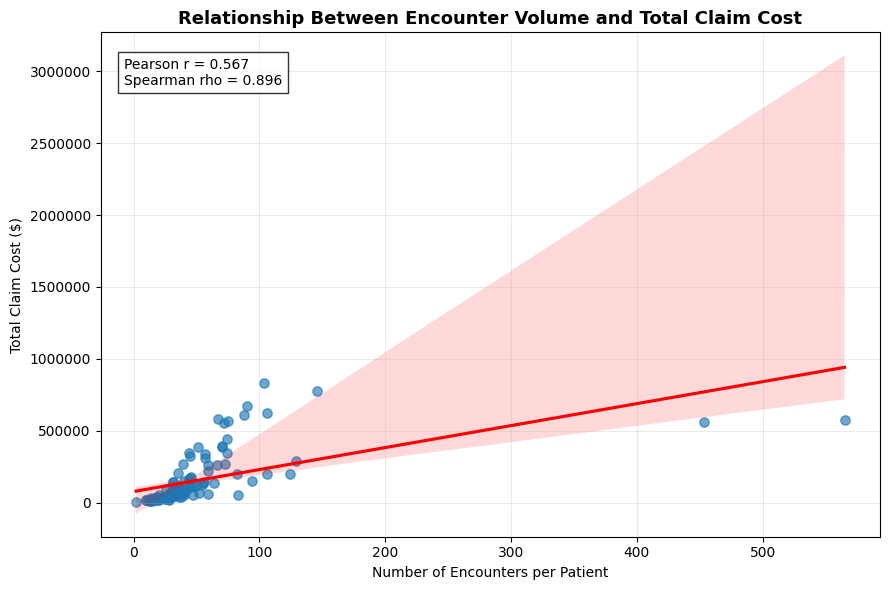

In [12]:

# Step 4B: Patient Utilization vs Total Claim Cost

plt.figure(figsize=(9, 6))

sns.regplot(
    data=patient_summary,
    x="Encounter_Count",
    y="Total_Claim_Cost",
    scatter_kws={"alpha": 0.65, "s": 45},
    line_kws={"color": "red"}
)

plt.title(
    "Relationship Between Encounter Volume and Total Claim Cost",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Number of Encounters per Patient")
plt.ylabel("Total Claim Cost ($)")

plt.ticklabel_format(style="plain", axis="y")
plt.grid(alpha=0.25)

plt.text(
    0.03, 0.95,
    f"Pearson r = {pearson_r:.3f}\nSpearman rho = {spearman_r:.3f}",
    transform=plt.gca().transAxes,
    va="top",
    bbox={"facecolor": "white", "alpha": 0.8}
)

plt.tight_layout()
plt.show()


In [18]:

# Step 5A: Examine encounter utilization distribution

print("PATIENT UTILIZATION SUMMARY")

display(
    patient_summary[
        ["Encounter_Count", "Total_Claim_Cost"]
    ].describe().round(2)
)

print("\nTOP 10 PATIENTS BY ENCOUNTER COUNT")

display(
    patient_summary.sort_values(
        "Encounter_Count",
        ascending=False
    ).head(10)
)


PATIENT UTILIZATION SUMMARY


,Encounter_Count,Total_Claim_Cost
count,108.00,108.00
mean,51.58,155612.49
std,69.23,186623.56
min,2.00,620.18
25%,24.00,33062.10
50%,36.00,70923.62
75%,57.00,198625.14
max,565.00,833106.46



TOP 10 PATIENTS BY ENCOUNTER COUNT


,PATIENT,Encounter_Count,Total_Claim_Cost,Average_Claim_Cost
41,57efda89-b582-bb08-8a2d-e06b2c184bfc,565,573455.98,1014.966336
79,bca1691f-8839-1d66-ed01-471134d55738,453,559347.96,1234.763709
13,2211f478-b7b4-7711-16cf-84ffb52b9d2b,146,775524.12,5311.809041
39,5693c080-f485-91e7-54b9-ad9a8c12af62,129,290845.47,2254.616047
24,355a4d50-2628-aa65-c336-deacf4d606fb,124,201179.44,1622.414839
29,3935e8a9-9b9f-fd00-fe22-bcb810d0330b,106,197136.64,1859.779623
71,a5816bea-ad10-431f-1281-47baa2cf249b,106,626414.37,5909.569528
87,ccaa0537-4e7f-99d8-8b79-c7c94c749579,104,833106.46,8010.639038
5,0b786670-17af-32e1-b2d2-f77c33874b30,94,151574.14,1612.490851
64,96de62ae-1b00-58d8-77f9-cd25414e16be,90,671192.62,7457.695778


In [17]:

# Step 5B: Identify high-utilization patients using IQR

Q1 = patient_summary["Encounter_Count"].quantile(0.25)
Q3 = patient_summary["Encounter_Count"].quantile(0.75)

IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

high_utilization = patient_summary[
    patient_summary["Encounter_Count"] > upper_limit
].copy()

print("OUTLIER ANALYSIS")
print(f"Q1: {Q1:.0f}")
print(f"Q3: {Q3:.0f}")
print(f"IQR: {IQR:.0f}")
print(f"Upper outlier threshold: {upper_limit:.1f}")
print(f"High-utilization patients: {len(high_utilization)}")

display(
    high_utilization[
        ["Encounter_Count", "Total_Claim_Cost"]
    ].sort_values("Encounter_Count", ascending=False)
)


OUTLIER ANALYSIS
Q1: 24
Q3: 57
IQR: 33
Upper outlier threshold: 106.5
High-utilization patients: 5


,Encounter_Count,Total_Claim_Cost
41,565,573455.98
79,453,559347.96
13,146,775524.12
39,129,290845.47
24,124,201179.44


In [16]:

# Step 6A: Prepare the predictive modeling dataset

from sklearn.model_selection import train_test_split

# Predictor: encounters per patient
X = patient_summary[["Encounter_Count"]]

# Target: total claim cost per patient
y = patient_summary["Total_Claim_Cost"]

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("PREDICTIVE MODEL DATA PREPARATION")
print("Training patients:", len(X_train))
print("Testing patients:", len(X_test))
print("Predictor:", X.columns.tolist())
print("Target: Total_Claim_Cost")


PREDICTIVE MODEL DATA PREPARATION
Training patients: 86
Testing patients: 22
Predictor: ['Encounter_Count']
Target: Total_Claim_Cost


In [19]:

# Step 6B: Train and evaluate Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict total claim costs for test patients
y_pred_linear = linear_model.predict(X_test)

# Evaluate model performance
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
linear_r2 = r2_score(y_test, y_pred_linear)

print("LINEAR REGRESSION MODEL RESULTS")
print(f"Mean Absolute Error (MAE): ${linear_mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${linear_rmse:,.2f}")
print(f"R-squared (R²): {linear_r2:.4f}")
print(f"Intercept: ${linear_model.intercept_:,.2f}")
print(f"Cost per additional encounter (slope): ${linear_model.coef_[0]:,.2f}")


LINEAR REGRESSION MODEL RESULTS
Mean Absolute Error (MAE): $87,283.70
Root Mean Squared Error (RMSE): $104,412.94
R-squared (R²): 0.4648
Intercept: $79,223.25
Cost per additional encounter (slope): $1,665.49


In [20]:

# Step 6C: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    min_samples_leaf=3
)

# Train model
rf_model.fit(X_train, y_train)

# Predict on test data
y_pred_rf = rf_model.predict(X_test)

# Evaluate
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

print("RANDOM FOREST REGRESSION RESULTS")
print(f"MAE: ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"R-squared (R²): {rf_r2:.4f}")


RANDOM FOREST REGRESSION RESULTS
MAE: $40,374.57
RMSE: $67,232.69
R-squared (R²): 0.7781


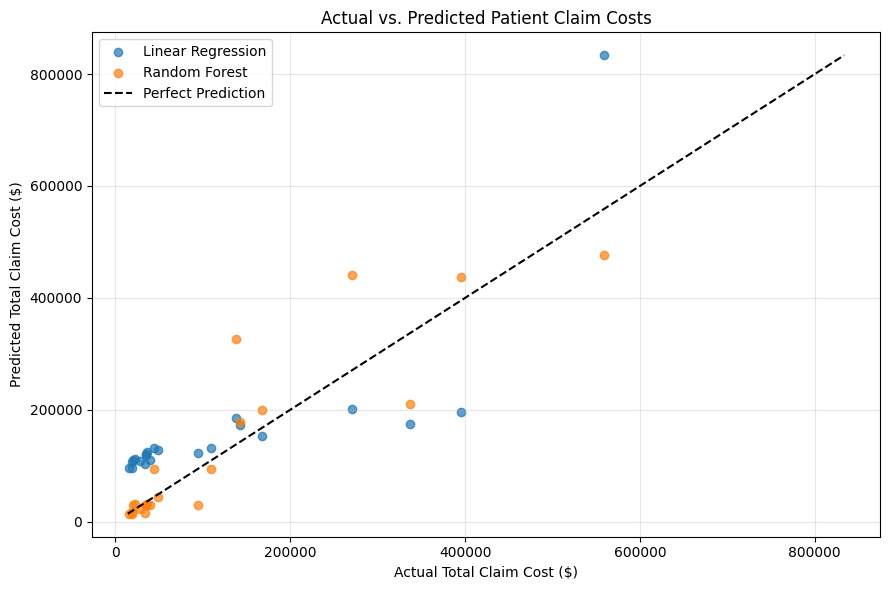

In [21]:

# Step 6D: Actual vs Predicted Claim Costs

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test, y_pred_linear,
    alpha=0.7,
    label="Linear Regression"
)

plt.scatter(
    y_test, y_pred_rf,
    alpha=0.7,
    label="Random Forest"
)

limits = [
    min(y_test.min(), y_pred_linear.min(), y_pred_rf.min()),
    max(y_test.max(), y_pred_linear.max(), y_pred_rf.max())
]

plt.plot(
    limits, limits,
    linestyle="--",
    color="black",
    label="Perfect Prediction"
)

plt.xlabel("Actual Total Claim Cost ($)")
plt.ylabel("Predicted Total Claim Cost ($)")
plt.title("Actual vs. Predicted Patient Claim Costs")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:

# Step 6E: Five-fold cross-validation

from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=3,
        random_state=42
    )
}

results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        }
    )

    results.append({
        "Model": name,
        "Mean MAE ($)": -scores["test_MAE"].mean(),
        "MAE Std ($)": scores["test_MAE"].std(),
        "Mean R2": scores["test_R2"].mean(),
        "R2 Std": scores["test_R2"].std()
    })

cv_results = pd.DataFrame(results)

display(cv_results.round(4))


,Model,Mean MAE ($),MAE Std ($),Mean R2,R2 Std
0,Linear Regression,113151.5448,20825.9118,0.2160,0.2150
1,Random Forest,72680.5476,22863.1157,0.5974,0.1371


In [23]:

# Step 7: Final predictive model comparison

model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Test MAE ($)": [linear_mae, rf_mae],
    "Test RMSE ($)": [linear_rmse, rf_rmse],
    "Test R2": [linear_r2, rf_r2],
    "CV Mean MAE ($)": cv_results["Mean MAE ($)"],
    "CV Mean R2": cv_results["Mean R2"]
})

display(model_comparison.round(3))

# Save comparison as CSV
model_comparison.to_csv(
    "Healthcare_Model_Comparison.csv",
    index=False
)

print("Model comparison CSV saved successfully.")

,Model,Test MAE ($),Test RMSE ($),Test R2,CV Mean MAE ($),CV Mean R2
0,Linear Regression,87283.698,104412.939,0.465,113151.545,0.216
1,Random Forest,40374.570,67232.694,0.778,72680.548,0.597


Model comparison CSV saved successfully.
